In [1]:
%pip install pandas numpy matplotlib seaborn openpyxl ipykernel

Note: you may need to restart the kernel to use updated packages.


# Unemployment Analysis in India using Python

## Objective
To explore regional and temporal trends in unemployment in India and examine changes around the COVID-19 pandemic.

## Tools Used
Python, pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Unemployment in India Project")
print("All libraries imported successfully!")

Unemployment in India Project
All libraries imported successfully!


## 1. Data Loading and Initial Inspection

The dataset was loaded into a Pandas DataFrame using the `read_csv()` function.

The initial inspection was performed to understand the structure of the dataset, including the number of rows and columns, column names, and sample records.

The `shape`, `head()`, and `columns` functions helped identify the available data and prepare it for further analysis.

In [3]:

import pandas as pd

df = pd.read_csv("Unemployment in India.csv")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

First 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Data types:
Region                                          str
 Date                                           str
 Frequency                                      str
 Estimated Unemployment Rate (%)            float64
 Estimated Employed                         float64
 Estimated Labour Participation Rate (%)    float64
Area                                            str
dtype: object

Missing values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate rows: 27


## 2. Data Cleaning and Preprocessing

Data cleaning is an important step before performing exploratory data analysis.

The following operations were performed:

- Removed unnecessary spaces from column names.
- Converted the Date column into a datetime format.
- Converted numerical columns into numeric data types.
- Checked missing values and duplicate records.
- Removed records missing essential fields required for the analysis.

These steps helped prepare the dataset for reliable calculations and visualizations.

In [5]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert Date column to datetime
df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

# Convert numerical columns to numeric format
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows missing key analysis fields
df = df.dropna(subset=[
    "Date",
    "Region",
    "Estimated Unemployment Rate (%)"
])

print("Cleaned dataset:", df.shape)
display(df.head())

Cleaned dataset: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


## 3. Region-wise Average Unemployment Rate

This analysis calculates the average unemployment rate for each state or region.

The `groupby()` function groups observations by region, while the `mean()` function calculates the average unemployment rate.

**Observation:**

The results help identify regions with relatively high and low average unemployment rates in the dataset. The regions should be compared using the calculated values rather than assumptions.

The averages describe the available historical observations and may be affected by differences in data coverage across regions.

In [6]:
region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

display(region_avg.to_frame("Average Unemployment Rate (%)").round(2))

,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


## 4. Monthly Unemployment Trend

The monthly trend analysis examines how the average unemployment rate changes over time.

The date column was used to organize observations by month, and the monthly average unemployment rate was calculated.

**Observation:**

The line chart shows the changes in average unemployment over the observed period. Peaks indicate months with higher average unemployment, while declines indicate months with lower average unemployment.

The months showing the largest changes should be identified from the actual chart.

In [7]:
monthly_avg = (
    df.set_index("Date")["Estimated Unemployment Rate (%)"]
    .resample("MS")
    .mean()
)

display(monthly_avg.round(2))

Date
2019-05-01     8.87
2019-06-01     9.30
2019-07-01     9.03
2019-08-01     9.64
2019-09-01     9.05
2019-10-01     9.90
2019-11-01     9.87
2019-12-01     9.50
2020-01-01     9.95
2020-02-01     9.96
2020-03-01    10.70
2020-04-01    23.64
2020-05-01    24.88
2020-06-01    11.90
Freq: MS, Name: Estimated Unemployment Rate (%), dtype: float64

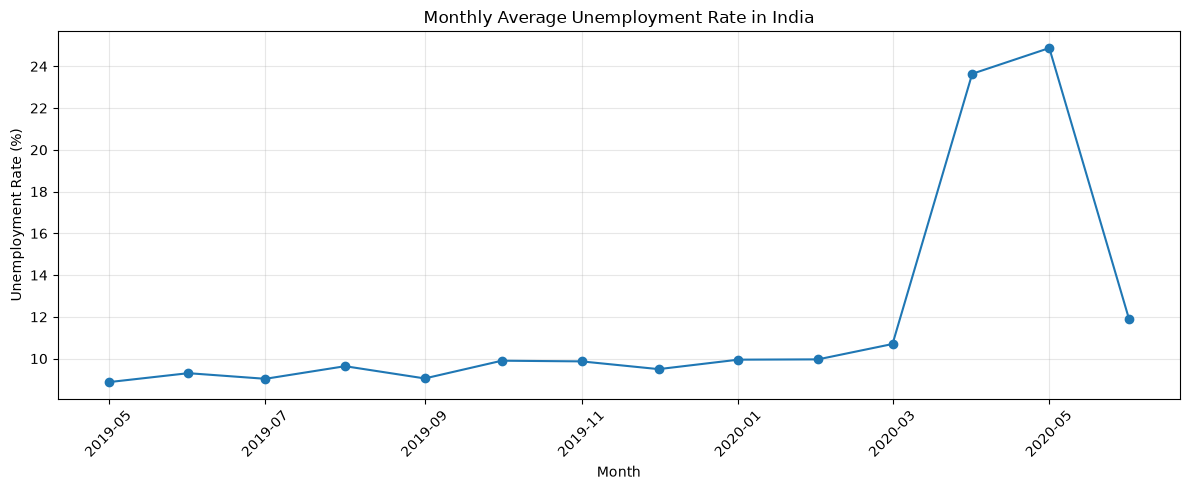

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. State-wise Time-Series Analysis

This analysis compares unemployment trends across three selected states: Rajasthan, Maharashtra, and Uttar Pradesh.

A line chart was used to show changes in their unemployment rates over time.

**Observation:**

The chart allows comparison of unemployment patterns across the selected states. It helps identify periods when rates increased or decreased and whether the states followed similar or different trends.

The conclusions should be based on the lines and values displayed in the chart.

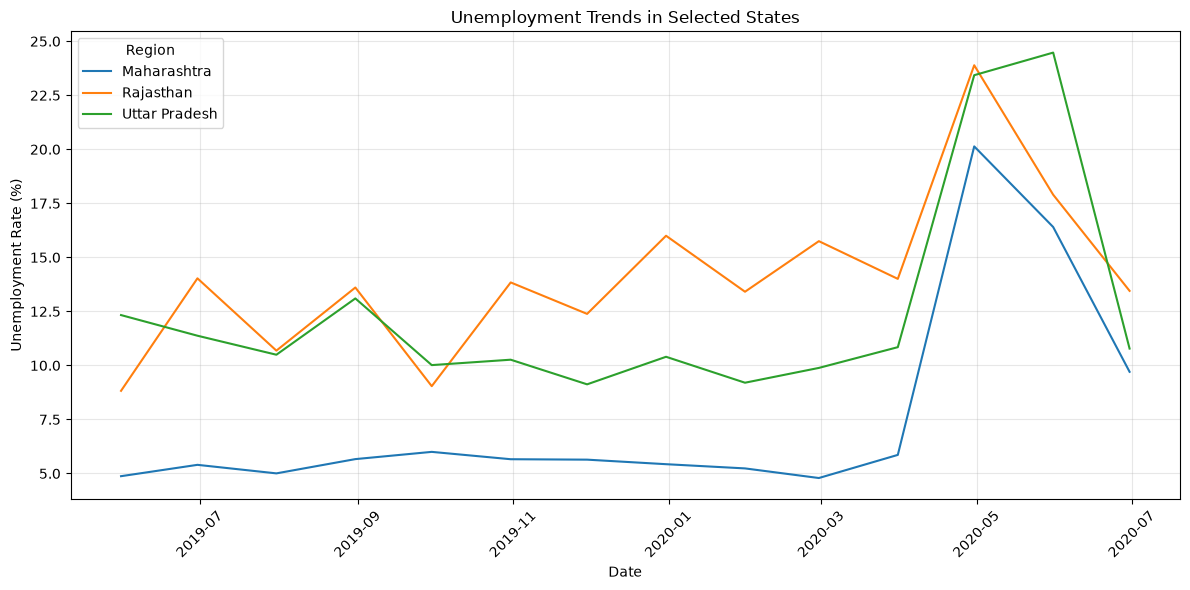

In [9]:
major_states = ["Rajasthan", "Maharashtra", "Uttar Pradesh"]

state_data = df[df["Region"].isin(major_states)]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_data,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    estimator="mean",
    errorbar=None
)

plt.title("Unemployment Trends in Selected States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Top 10 Regions with the Highest Average Unemployment Rate

A bar chart was created to display the ten regions with the highest average unemployment rates in the dataset.

The regions were ranked according to their calculated mean unemployment rates.

**Observation:**

The bar chart highlights the regions with the highest average unemployment rates among those included in the analysis.

The ranking reflects this dataset and its historical period. It should not be treated as a ranking of current unemployment rates.

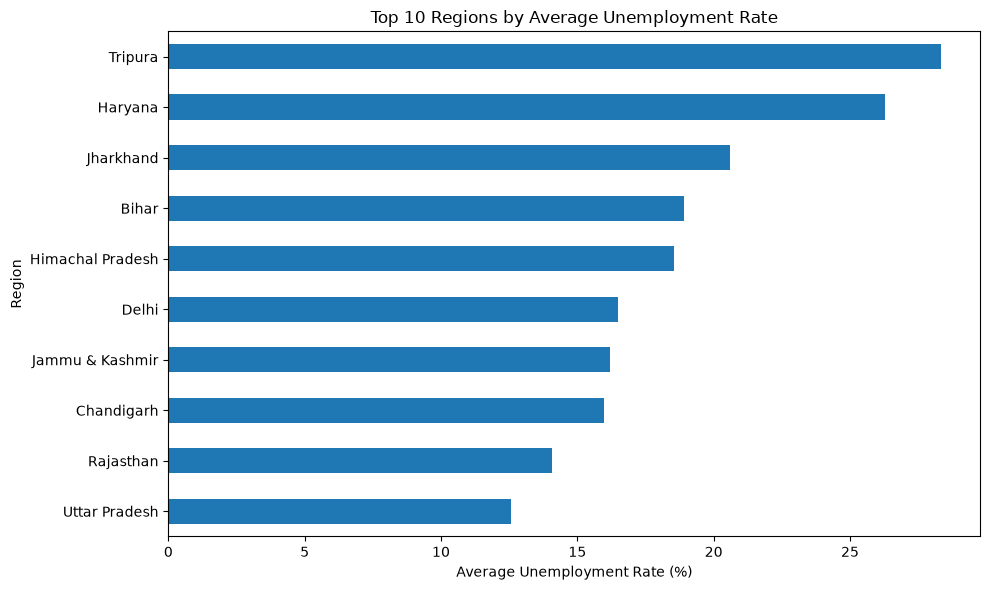

In [10]:
top10 = region_avg.head(10).sort_values()

plt.figure(figsize=(10, 6))
top10.plot(kind="barh")

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

## 7. Correlation Analysis

A correlation heatmap was created to examine relationships among the following numerical indicators:

- Estimated Unemployment Rate (%)
- Estimated Employed
- Estimated Labour Participation Rate (%)

Correlation values range from -1 to +1.

- A positive correlation indicates that two variables tend to increase or decrease together.
- A negative correlation indicates that one variable tends to increase as the other decreases.
- A value near zero indicates a weak linear relationship.

**Observation:**

The heatmap displays the strength and direction of the relationships between the selected indicators. The actual correlation values should be used to describe the relationships observed in the dataset.

Correlation does not establish a cause-and-effect relationship.

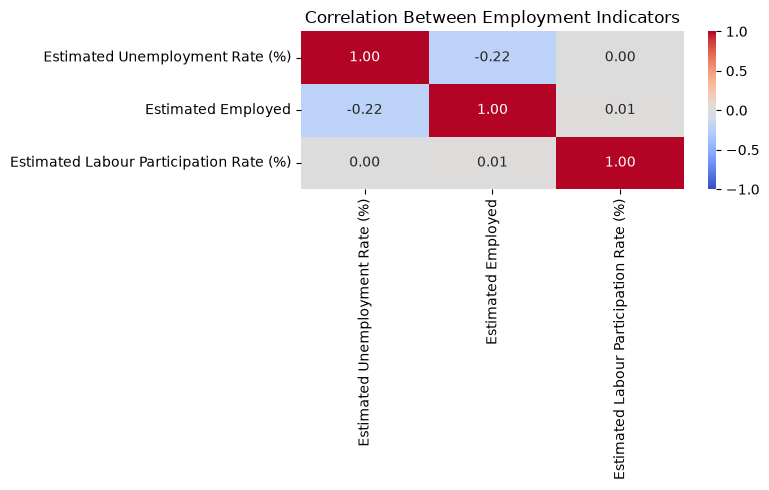

In [11]:
corr_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[corr_cols].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

## 8. Pre-COVID vs COVID Period Comparison

The dataset was divided into two periods using 1 March 2020 as the analysis cutoff:

- **Pre-COVID:** Observations dated before 1 March 2020.
- **COVID Period:** Observations dated on or after 1 March 2020.

The mean unemployment rate was calculated for each period and compared using a bar chart.

**Observation:**

The bar chart compares the average unemployment rate before the selected cutoff with the average during the COVID period covered by the dataset.

The difference between the two averages indicates how unemployment changed between these periods in the available data. The calculated values should be used to determine the direction and size of the difference.

This comparison alone cannot prove that COVID-19 caused the change. The dataset mainly covers 2019–2020 and does not describe current unemployment conditions.

C:\Users\mahav\AppData\Local\Temp\ipykernel_10620\3865706265.py:20: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(


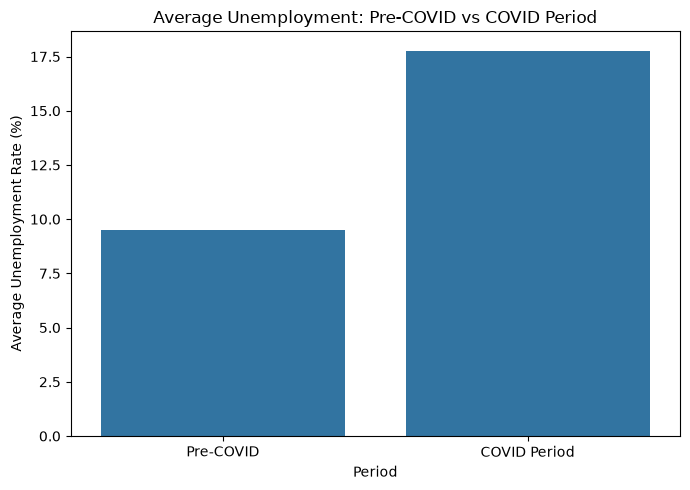

Period
COVID Period    17.77
Pre-COVID        9.51
Name: Estimated Unemployment Rate (%), dtype: float64


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load dataset if df is not already available
try:
    df
except NameError:
    df = pd.read_csv("Unemployment in India.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Convert unemployment rate to numeric
rate_col = "Estimated Unemployment Rate (%)"
df[rate_col] = pd.to_numeric(df[rate_col], errors="coerce")

# Convert dates
df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

# Create Pre-COVID and COVID Period groups
cutoff = pd.Timestamp("2020-03-01")
df["Period"] = np.where(
    df["Date"] < cutoff,
    "Pre-COVID",
    "COVID Period"
)

# Remove rows missing chart data
chart_df = df.dropna(subset=["Period", rate_col])

# Draw bar chart
plt.figure(figsize=(7, 5))
sns.barplot(
    data=chart_df,
    x="Period",
    y=rate_col,
    estimator="mean",
    errorbar=None
)

plt.title("Average Unemployment: Pre-COVID vs COVID Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print(chart_df.groupby("Period")[rate_col].mean().round(2))

## 9. Conclusion

This project used Python to perform exploratory data analysis on historical unemployment data from India.

Pandas and NumPy were used to clean and analyze the dataset, while Matplotlib and Seaborn were used to create visualizations.

The analysis examined regional averages, monthly trends, selected state comparisons, the top ten regions by average unemployment, correlations between employment indicators, and differences between the pre-COVID and COVID periods.

The charts and calculations help summarize patterns in the available data. However, the findings are limited to the dataset's coverage, dates, and data quality.

This project demonstrates how Python can be used for data cleaning, exploratory data analysis, statistical summaries, and visualization.

## 10. Dataset Source

Kaggle — Unemployment in India

https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india

## 11. Key Learning Outcomes

- Learned to load and inspect CSV data using Pandas.
- Practiced checking missing values and converting data types.
- Learned to calculate averages using `groupby()` and `mean()`.
- Created line charts, bar charts, and a correlation heatmap.
- Practiced date-based grouping and period comparisons.
- Learned to interpret visualizations and write data-based observations.